<a href="https://colab.research.google.com/github/MilkySon/Quality-Management/blob/main/RP3_%EA%B7%B8%EB%A6%BC_%EA%B7%B8%EB%A6%AC%EA%B8%B0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# 1. 필요한 라이브러리 설치 및 임포트
import pandas as pd
import matplotlib.pyplot as plt

# 2. 엑셀 파일 업로드 코드 (코랩 실행 시 파일 선택 창이 뜸)
from google.colab import files
uploaded = files.upload()


Saving Prajapati_2012_Table1A.xlsx to Prajapati_2012_Table1A.xlsx


In [3]:

# 업로드한 파일명 확인 후 파일 경로 지정 (예: 'Prajapati_2012_Table1A.xlsx')
file_name = list(uploaded.keys())[0]

# 3. 데이터 읽어오기
df = pd.read_excel(file_name, header=3, index_col=0)


In [7]:
df.tail()

,X1,X2,X3,X4,X̄,R
S. NO.,,,,,,
397,62.04,62.04,62.02,61.98,62.0200,0.06
398,62.05,61.98,62.05,61.93,62.0025,0.12
399,62.08,62.02,62.04,61.90,62.0100,0.18
400,61.98,61.96,61.99,62.02,61.9875,0.06
Total,NaN,NaN,NaN,NaN,24800.7000,36.82


In [8]:
# 'Total' 행 제거
df = df.drop(index='Total', errors='ignore')

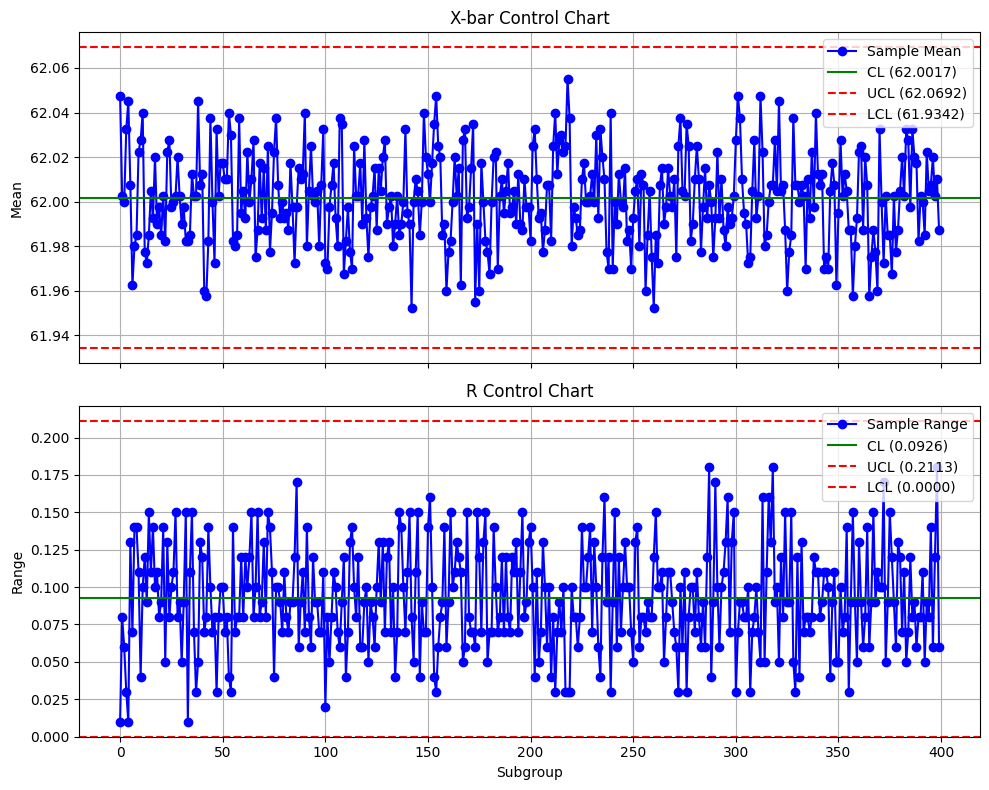

In [9]:

# 4. 부분군 데이터 추출 (X1, X2, X3, X4)
subgroups = df[['X1', 'X2', 'X3', 'X4']]

# 5. X-bar(평균) 및 R(범위) 계산
# 각 부분군의 평균 (X-bar)
x_bar = subgroups.mean(axis=1)
# 각 부분군의 범위 (R = 최댓값 - 최솟값)
r_range = subgroups.max(axis=1) - subgroups.min(axis=1)

# 전체 평균의 평균 (Grand Mean, X-double-bar)
grand_mean = x_bar.mean()
# 평균 범위 (R-bar)
r_bar = r_range.mean()

# 관리도 계수 (n=4일 때의 통계적 관리도 상수: A2 = 0.729, D3 = 0, D4 = 2.282)
# n=4 기준 표준 상수 적용
A2 = 0.729
D3 = 0
D4 = 2.282

# X-bar 관리도 한계선 계산
xbar_ucl = grand_mean + A2 * r_bar
xbar_lcl = grand_mean - A2 * r_bar

# R 관리도 한계선 계산
r_ucl = D4 * r_bar
r_lcl = D3 * r_bar

# 6. 관리도 시각화
fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

# (1) X-bar Chart
axes[0].plot(x_bar.values, marker='o', color='b', linestyle='-', label='Sample Mean')
axes[0].axhline(grand_mean, color='g', linestyle='-', label=f'CL ({grand_mean:.4f})')
axes[0].axhline(xbar_ucl, color='r', linestyle='--', label=f'UCL ({xbar_ucl:.4f})')
axes[0].axhline(xbar_lcl, color='r', linestyle='--', label=f'LCL ({xbar_lcl:.4f})')
axes[0].set_title('X-bar Control Chart')
axes[0].set_ylabel('Mean')
axes[0].legend(loc='upper right')
axes[0].grid(True)

# (2) R Chart
axes[1].plot(r_range.values, marker='o', color='b', linestyle='-', label='Sample Range')
axes[1].axhline(r_bar, color='g', linestyle='-', label=f'CL ({r_bar:.4f})')
axes[1].axhline(r_ucl, color='r', linestyle='--', label=f'UCL ({r_ucl:.4f})')
axes[1].axhline(r_lcl, color='r', linestyle='--', label=f'LCL ({r_lcl:.4f})')
axes[1].set_title('R Control Chart')
axes[1].set_xlabel('Subgroup')
axes[1].set_ylabel('Range')
axes[1].legend(loc='upper right')
axes[1].grid(True)

plt.tight_layout()
plt.show()

Normality (Shapiro-Wilk): W=0.96552, p=4.4233e-19, N=1600
Reject normality at alpha=0.05


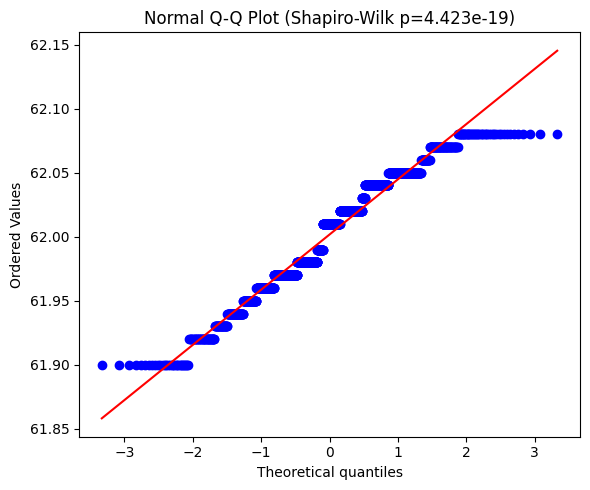


X-bar chart
  Rule 1: None
  Rule 2: None
  Rule 3: 212, 213, 215, 216, 218, 219, 220, 366, 367, 369, 370
  Rule 4: 48, 49, 50, 51, 52, 53, 54, 55, 212, 213, 214, 215, 216, 217, 218, 219, 220
  Rule 5: None


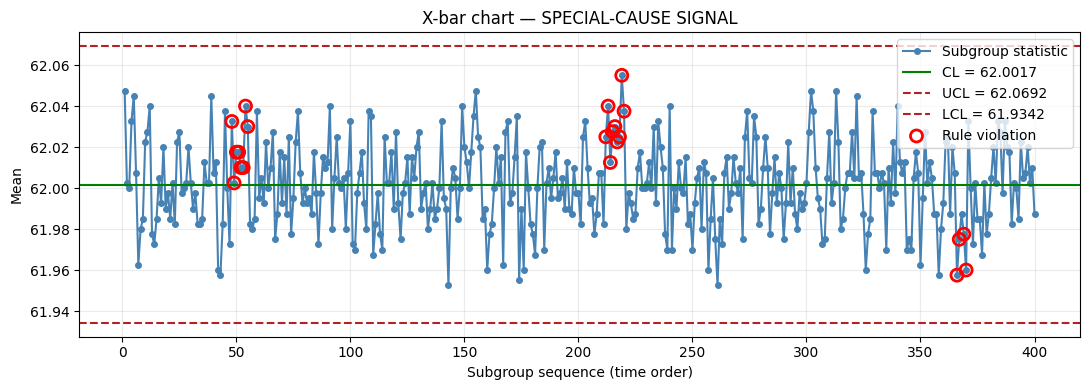


R chart
  Rule 1: None
  Rule 2: 4, 5, 218, 219, 220
  Rule 3: 1, 3, 4, 5
  Rule 4: None
  Rule 5: None


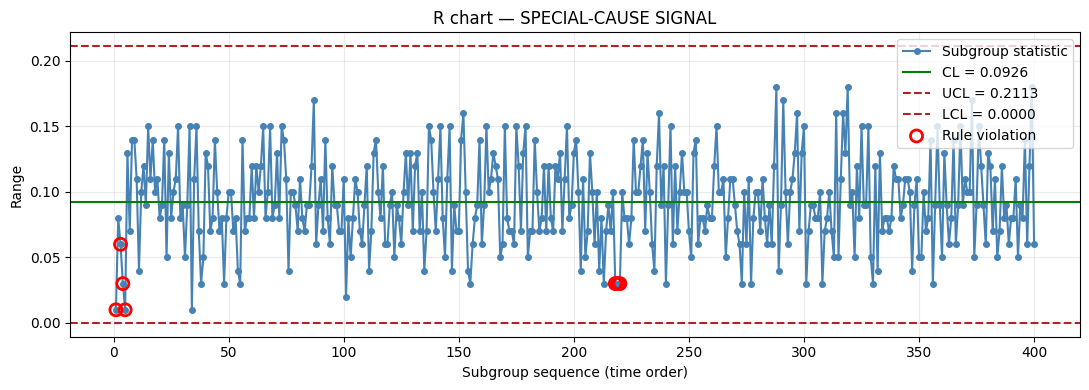

,Chart,Status,Rule 1,Rule 2,Rule 3,Rule 4,Rule 5
0,X-bar,SIGNAL DETECTED,0,0,11,17,0
1,R,SIGNAL DETECTED,0,5,4,0,0


Conclusion: Investigate special causes; do not delete observations without a documented reason.


In [10]:
# === Paste this entire cell immediately after the existing plt.show() cell ===
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import shapiro, probplot

ALPHA = 0.05

# Normality applies to the individual observations, not to the subgroup ranges.
measurements = pd.to_numeric(subgroups.stack(), errors='coerce').dropna().to_numpy(dtype=float)
if len(measurements) < 3:
    raise ValueError('Normality test requires at least 3 valid observations.')
if len(measurements) > 5000:
    print('Note: Shapiro-Wilk p-values may be inaccurate for N > 5000.')
if np.ptp(measurements) == 0:
    print('Normality cannot be assessed: all measurements are identical.')
else:
    W, p = shapiro(measurements)
    print(f'Normality (Shapiro-Wilk): W={W:.5f}, p={p:.5g}, N={len(measurements)}')
    print('Reject normality at alpha=0.05' if p < ALPHA else 'Insufficient evidence to reject normality at alpha=0.05')
    fig, ax = plt.subplots(figsize=(6, 5))
    probplot(measurements, dist='norm', plot=ax)
    ax.set_title(f'Normal Q-Q Plot (Shapiro-Wilk p={p:.4g})')
    plt.tight_layout()
    plt.show()

# Course lecture rules: 1 point outside 3 sigma; 2/3 beyond 2 sigma;
# 4/5 beyond 1 sigma; 8 on same side of CL; 8 strictly increasing/decreasing.
# For R charts, sigma here refers to the chart statistic's implied 3-sigma scale.
def detect_rules(values, cl, ucl, lcl):
    y = np.asarray(values, dtype=float)
    if not np.all(np.isfinite(y)):
        raise ValueError('Missing or nonfinite subgroup statistics. Clean the data before testing.')
    n = len(y)
    upper_step = (ucl - cl) / 3.0
    lower_step = (cl - lcl) / 3.0
    if upper_step <= 0 or lower_step <= 0:
        raise ValueError('Invalid control limits: require LCL < CL < UCL.')
    flags = {f'Rule {i}': set() for i in range(1, 6)}

    for i in range(n):
        if y[i] > ucl or y[i] < lcl:
            flags['Rule 1'].add(i)

    # Rule 2 and 3: all qualifying points must be on the SAME side.
    for i in range(n - 2):
        window = np.arange(i, i + 3)
        high = window[y[window] > cl + 2 * upper_step]
        low = window[y[window] < cl - 2 * lower_step]
        if len(high) >= 2 or len(low) >= 2:
            flags['Rule 2'].update(high if len(high) >= 2 else low)

    for i in range(n - 4):
        window = np.arange(i, i + 5)
        high = window[y[window] > cl + upper_step]
        low = window[y[window] < cl - lower_step]
        if len(high) >= 4 or len(low) >= 4:
            flags['Rule 3'].update(high if len(high) >= 4 else low)

    for i in range(n - 7):
        window = np.arange(i, i + 8)
        if np.all(y[window] > cl) or np.all(y[window] < cl):
            flags['Rule 4'].update(window.tolist())
        diffs = np.diff(y[window])
        if np.all(diffs > 0) or np.all(diffs < 0):
            flags['Rule 5'].update(window.tolist())
    return flags

charts = {
    'X-bar': (x_bar, grand_mean, xbar_ucl, xbar_lcl),
    'R': (r_range, r_bar, r_ucl, r_lcl),
}
results = {}
summary = []
for name, (series, cl, ucl, lcl) in charts.items():
    flags = detect_rules(series, cl, ucl, lcl)
    results[name] = flags
    violated = any(flags.values())
    summary.append({'Chart': name, 'Status': 'SIGNAL DETECTED' if violated else 'NO SIGNAL DETECTED',
                    **{rule: len(indices) for rule, indices in flags.items()}})
    print(f'\n{name} chart')
    for rule, indices in flags.items():
        # Subgroup labels reflect the ORIGINAL Excel index, not necessarily 1..N.
        labels = [str(series.index[i]) for i in sorted(indices)]
        print(f'  {rule}: {", ".join(labels) if labels else "None"}')

    x = np.arange(1, len(series) + 1)
    y = series.to_numpy(dtype=float)
    fig, ax = plt.subplots(figsize=(11, 4))
    ax.plot(x, y, '-o', color='steelblue', markersize=4, label='Subgroup statistic')
    ax.axhline(cl, color='green', label=f'CL = {cl:.4f}')
    ax.axhline(ucl, color='firebrick', linestyle='--', label=f'UCL = {ucl:.4f}')
    ax.axhline(lcl, color='firebrick', linestyle='--', label=f'LCL = {lcl:.4f}')
    marked = set().union(*flags.values())
    if marked:
        positions = np.array(sorted(marked), dtype=int)
        ax.scatter(x[positions], y[positions], s=75, facecolors='none',
                   edgecolors='red', linewidths=2, zorder=5, label='Rule violation')
    ax.set_title(f'{name} chart — {"SPECIAL-CAUSE SIGNAL" if violated else "No selected-rule signal"}')
    ax.set_xlabel('Subgroup sequence (time order)')
    ax.set_ylabel('Mean' if name == 'X-bar' else 'Range')
    ax.grid(alpha=.25)
    ax.legend(loc='best')
    plt.tight_layout()
    plt.show()

report = pd.DataFrame(summary)
display(report)
if all(row['Status'] == 'NO SIGNAL DETECTED' for row in summary):
    print('Conclusion: No signals under the five selected rules in either chart; this does not prove stability.')
else:
    print('Conclusion: Investigate special causes; do not delete observations without a documented reason.')

# NOTE: R-chart LCL=0 is a truncated 3-sigma bound. For n=4, use of
# the 1-sigma/2-sigma zones based on (CL-LCL)/3 is only an approximation.
# For rigorous Minitab-equivalent zone tests, use its exact test definitions.
